# Phase 2 — Research-based BiLSTM magnitude estimation
Run all cells from the project root or `bilstm/`. All model, training, tuning and evaluation code is in this notebook; outputs are under `bilstm/phase2_bilstm_results/`. Existing splits are preserved. Only the primary regression task is trained.

[Graves & Schmidhuber (2005)](https://www.cs.toronto.edu/~graves/nn_2005.pdf), sections II–III, combine forward/backward recurrent processing and full backpropagation through time. [Schuster & Paliwal (1997)](https://doi.org/10.1109/78.650093) introduced bidirectional recurrent networks. Here the **last layer's final forward and backward hidden states** are concatenated, followed by dropout and a scalar linear head. This adapts their bidirectional principle to sequence-level magnitude regression, not framewise speech classification. PyTorch's standard LSTM lacks peepholes, so it is not an exact copy of the paper's cell. AdamW trains all weights and biases through BPTT; no CNN or attention is used.

The supplied files lack feature names, event IDs and target timestamps. Causal ordering and event-disjoint splits cannot be established. Results are magnitude estimation on the supplied splits, **not future earthquake forecasting**.

In [1]:
from pathlib import Path
import os, sys
ROOT = Path.cwd().resolve()
if (ROOT / "bilstm" / "bilstm_dataset").is_dir():
    ROOT = ROOT / "bilstm"
assert (ROOT / "bilstm_dataset").is_dir(), "Run from project root or bilstm."
# Install missing dependencies: python -m pip install --target bilstm/.notebook-runtime optuna nbclient ipykernel
if (ROOT / ".notebook-runtime").exists():
    sys.path.insert(0, str(ROOT / ".notebook-runtime"))
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
import json, time, random, hashlib, math, platform, pickle
import numpy as np
import pandas as pd
import torch
from torch import nn
import optuna
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image
OUT = ROOT / "phase2_bilstm_results"
OUT.mkdir(exist_ok=True)
(OUT / "runs").mkdir(exist_ok=True)
SEED, MAX_EPOCHS, PATIENCE, N_TRIALS = 42, 50, 8, 15
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(min(4, os.cpu_count() or 1))
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.use_deterministic_algorithms(True)
optuna.logging.set_verbosity(optuna.logging.WARNING)
def seed_all(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
seed_all(SEED)
def atomic_json(path, value):
    path = Path(path)
    temp = path.with_name(path.name + ".tmp")
    temp.write_text(json.dumps(value, indent=2, allow_nan=False), encoding="utf-8")
    temp.replace(path)
def save_torch(path, value):
    path = Path(path)
    temp = path.with_name(path.name + ".tmp")
    torch.save(value, temp)
    temp.replace(path)
def sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()
def sync():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
environment = {"python": platform.python_version(), "torch": str(torch.__version__),
               "numpy": np.__version__, "pandas": pd.__version__, "optuna": optuna.__version__,
               "matplotlib": matplotlib.__version__, "device": str(DEVICE),
               "gpu": torch.cuda.get_device_name() if DEVICE.type == "cuda" else None,
               "seed": SEED, "max_epochs": MAX_EPOCHS, "patience": PATIENCE}
atomic_json(OUT / "environment.json", environment)
print(f"Device: {DEVICE}; GPU: {environment['gpu']}; outputs: {OUT}")


C:\Users\choud\Desktop\Minor project\bilstm\.notebook-runtime\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Matplotlib is building the font cache; this may take a moment.


Device: cuda; GPU: NVIDIA GeForce RTX 3050 Laptop GPU; outputs: C:\Users\choud\Desktop\Minor project\bilstm\phase2_bilstm_results


## Data and inverse transformation
Use the primary PT, or NPZ fallback if PT is absent. Do not substitute the station-grouped alternative. No scaler object is supplied: recover the existing affine inverse from **training-only saved scaled/raw pairs**, verify all development pairs, and save the coefficients and provenance. This does not refit or replace the dataset's scaling. The prior audit suggests raw ≈ 7.1 × scaled + 1.5. Test targets are checked only in final evaluation.

In [2]:
data_path = ROOT / "bilstm_dataset" / "bilstm_dataset_seq20.pt"
if data_path.exists():
    data = torch.load(data_path, map_location="cpu", weights_only=True)
else:
    data_path = data_path.with_suffix(".npz")
    with np.load(data_path, allow_pickle=False) as archive:
        data = {k: torch.from_numpy(archive[k].copy()) for k in archive.files}
DATA_HASH = sha256(data_path)
for split in ("train", "val"):
    x = data[f"X_{split}"].float()
    y = data[f"y_{split}"].float().reshape(-1)
    raw = data[f"y_{split}_raw"].float().reshape(-1)
    assert x.ndim == 3 and tuple(x.shape[1:]) == (20, 36)
    assert len(x) == len(y) == len(raw)
    assert all(torch.isfinite(t).all() for t in (x, y, raw))
ys = data["y_train"].numpy().reshape(-1).astype(np.float64)
yr = data["y_train_raw"].numpy().reshape(-1).astype(np.float64)
coeff, *_ = np.linalg.lstsq(np.column_stack((ys, np.ones_like(ys))), yr, rcond=None)
SCALE, OFFSET = map(float, coeff)
assert SCALE > 0
max_inverse_error = {}
for split in ("train", "val"):
    reconstructed = data[f"y_{split}"].double().reshape(-1) * SCALE + OFFSET
    actual = data[f"y_{split}_raw"].double().reshape(-1)
    err = float((reconstructed - actual).abs().max())
    assert err < 2e-6, f"Target inverse not established: {split}, error={err}"
    max_inverse_error[split] = err
TARGET = {"name": "supplied scaled magnitude regression target",
          "inverse": "magnitude = scale * scaled_target + offset",
          "scale": SCALE, "offset": OFFSET,
          "origin": "Recovered from saved training scaled/raw pairs; no scaler object supplied.",
          "verification_max_abs_error": max_inverse_error,
          "timing": "Unknown; future forecasting interpretation not established."}
atomic_json(OUT / "target_transform.json", TARGET)
protocol = {"version": 1, "dataset_sha256": DATA_HASH, "input_shape": [20, 36],
            "objective": "validation raw-magnitude MAE", "loss": "scaled-target MSE",
            "optimizer": "AdamW", "clip_norm": 1.0, "epochs": MAX_EPOCHS,
            "patience": PATIENCE, "seed": SEED, "target": TARGET,
            "search": {"hidden_size": [32, 64, 128], "layers": [1, 2], "dropout": [0.1, 0.4],
                       "lr": [1e-4, 3e-3], "weight_decay": [1e-6, 1e-3], "batch_size": [32, 64, 128]}}
EXPERIMENT = hashlib.sha256(json.dumps(protocol, sort_keys=True).encode()).hexdigest()
manifest_path = OUT / "experiment_manifest.json"
if manifest_path.exists():
    assert json.loads(manifest_path.read_text())["fingerprint"] == EXPERIMENT, \
        "Protocol/data changed. Preserve old results and use a new output directory."
else:
    atomic_json(manifest_path, {"fingerprint": EXPERIMENT, **protocol})
DEV = {split: (data[f"X_{split}"].float().to(DEVICE),
               data[f"y_{split}"].float().reshape(-1).to(DEVICE)) for split in ("train", "val")}
TRAIN_MEAN = float(data["y_train_raw"].double().mean())
print(f"Development: {len(DEV['train'][0])} train, {len(DEV['val'][0])} validation; "
      f"inverse magnitude = {SCALE:.8f} * scaled + {OFFSET:.8f}")


Development: 5629 train, 1191 validation; inverse magnitude = 7.09999995 * scaled + 1.50000002


## Model, baseline and resumable fitting
Use scaled-target MSE, AdamW, gradient norm clipping at 1.0, maximum 50 epochs and patience 8. Validation MAE selects checkpoints. Training loss is also measured in evaluation mode for comparable curves; stochastic training loss is saved separately.

Baseline: hidden size 64 per direction, one layer, dropout 0.2, learning rate 0.001, weight decay 0.0001, batch size 64. Last checkpoints retain optimizer, RNG, history and patience. Completed runs are reused only when identities match. Run only one copy of the notebook at a time.

In [3]:
class BiLSTMMagnitude(nn.Module):
    def __init__(self, hidden_size=64, layers=1, dropout=0.2):
        super().__init__()
        self.lstm = nn.LSTM(36, hidden_size, num_layers=layers, bidirectional=True,
                            batch_first=True, dropout=dropout if layers > 1 else 0.0)
        self.dropout = nn.Dropout(dropout)
        self.head = nn.Linear(2 * hidden_size, 1)
    def forward(self, x):
        _, (h_n, _) = self.lstm(x)
        # Last layer's final forward/backward states; not the last output timestep.
        return self.head(self.dropout(torch.cat((h_n[-2], h_n[-1]), dim=1))).squeeze(-1)

def make_model(config):
    return BiLSTMMagnitude(**{k: config[k] for k in ("hidden_size", "layers", "dropout")}).to(DEVICE)

@torch.inference_mode()
def predict_scaled(model, x, batch_size=512):
    model.eval()
    return torch.cat([model(x[i:i + batch_size].to(DEVICE)).cpu()
                      for i in range(0, len(x), batch_size)]).numpy()

def dev_metrics(model, split):
    x, y = DEV[split]
    delta = predict_scaled(model, x).astype(np.float64) - y.cpu().numpy().astype(np.float64)
    mse = float(np.mean(delta ** 2))
    return {"loss": mse, "mae": float(np.mean(np.abs(delta)) * SCALE),
            "rmse": float(np.sqrt(mse) * SCALE)}

def rng_state():
    return {"python": random.getstate(), "numpy": np.random.get_state(),
            "torch": torch.get_rng_state(),
            "cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else []}

def restore_rng(s):
    random.setstate(s["python"])
    np.random.set_state(s["numpy"])
    torch.set_rng_state(s["torch"])
    if torch.cuda.is_available() and s["cuda"]:
        torch.cuda.set_rng_state_all(s["cuda"])

def fit_run(name, config, trial=None):
    folder = OUT / "runs" / name
    folder.mkdir(exist_ok=True)
    best_path, last_path, summary_path = (folder / f for f in ("best.pt", "last.pt", "summary.json"))
    identity = {"experiment": EXPERIMENT, "config": config, "seed": SEED}
    if summary_path.exists():
        summary = json.loads(summary_path.read_text())
        assert summary["identity"] == identity and best_path.exists(), "Cached run mismatch."
        return summary, best_path
    seed_all(SEED)
    model = make_model(config)
    optimizer = torch.optim.AdamW(model.parameters(), lr=config["lr"], weight_decay=config["weight_decay"])
    assert {id(p) for g in optimizer.param_groups for p in g["params"]} == \
           {id(p) for p in model.parameters() if p.requires_grad}
    history, best_mae, bad_epochs, elapsed = [], math.inf, 0, 0.0
    if last_path.exists():
        # Only load our trusted local resumable checkpoints with weights_only=False.
        state = torch.load(last_path, map_location="cpu", weights_only=False)
        assert state["identity"] == identity
        model.load_state_dict(state["model"])
        optimizer.load_state_dict(state["optimizer"])
        restore_rng(state["rng"])
        history, best_mae = state["history"], state["best_mae"]
        bad_epochs, elapsed = state["bad_epochs"], state["elapsed_seconds"]
    x, y = DEV["train"]
    for epoch in range(len(history) + 1, MAX_EPOCHS + 1):
        if bad_epochs >= PATIENCE:
            break
        sync()
        tick = time.perf_counter()
        model.train()
        order = torch.randperm(len(x), device=DEVICE)
        total = torch.zeros((), device=DEVICE)
        for start in range(0, len(x), config["batch_size"]):
            idx = order[start:start + config["batch_size"]]
            optimizer.zero_grad(set_to_none=True)
            loss = nn.functional.mse_loss(model(x[idx]), y[idx])
            assert torch.isfinite(loss)
            loss.backward()
            if epoch == 1 and start == 0:
                assert all(p.grad is not None and torch.isfinite(p.grad).all()
                           for p in model.parameters() if p.requires_grad)
                assert any("_reverse" in n for n, p in model.named_parameters() if p.grad is not None)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            total += loss.detach() * len(idx)
        train, val = dev_metrics(model, "train"), dev_metrics(model, "val")
        sync()
        elapsed += time.perf_counter() - tick
        row = {"epoch": epoch, "optimization_loss": float(total.cpu()) / len(x),
               "train_loss": train["loss"], "train_mae": train["mae"], "train_rmse": train["rmse"],
               "val_loss": val["loss"], "val_mae": val["mae"], "val_rmse": val["rmse"],
               "elapsed_seconds": elapsed}
        history.append(row)
        if val["mae"] < best_mae:
            best_mae, bad_epochs = val["mae"], 0
            save_torch(best_path, {
                "model_state_dict": {k: v.detach().cpu() for k, v in model.state_dict().items()},
                "architecture": {k: config[k] for k in ("hidden_size", "layers", "dropout")},
                "input_shape": [20, 36], "hyperparameters": config, "target_definition": TARGET,
                "best_epoch": epoch, "validation_mae": best_mae, "identity": identity})
        else:
            bad_epochs += 1
        save_torch(last_path, {"identity": identity, "model": model.state_dict(),
                              "optimizer": optimizer.state_dict(), "rng": rng_state(),
                              "history": history, "best_mae": best_mae,
                              "bad_epochs": bad_epochs, "elapsed_seconds": elapsed})
        pd.DataFrame(history).to_csv(folder / "history.csv", index=False)
        if trial is not None:
            trial.report(val["mae"], step=epoch)
            if trial.should_prune():
                trial.set_user_attr("training_seconds", elapsed)
                raise optuna.TrialPruned()
    best = torch.load(best_path, map_location="cpu", weights_only=True)
    best_row = history[best["best_epoch"] - 1]
    summary = {"identity": identity, "run": name, "best_epoch": best["best_epoch"],
               "epochs_run": len(history), "training_seconds": elapsed,
               "parameter_count": sum(p.numel() for p in model.parameters()),
               "train_loss": best_row["train_loss"], "train_mae": best_row["train_mae"],
               "validation_loss": best_row["val_loss"], "validation_mae": best_row["val_mae"],
               "validation_rmse": best_row["val_rmse"],
               "stopping_reason": "early_stopping" if bad_epochs >= PATIENCE else "max_epochs"}
    atomic_json(summary_path, summary)
    return summary, best_path

BASELINE = {"hidden_size": 64, "layers": 1, "dropout": 0.2, "lr": 0.001,
            "weight_decay": 0.0001, "batch_size": 64}
baseline_summary, baseline_path = fit_run("baseline", BASELINE)
print(f"Baseline: best epoch={baseline_summary['best_epoch']}, "
      f"validation MAE={baseline_summary['validation_mae']:.5f}, "
      f"RMSE={baseline_summary['validation_rmse']:.5f}, "
      f"training={baseline_summary['training_seconds']:.1f}s")


Baseline: best epoch=23, validation MAE=0.28931, RMSE=0.37867, training=13.4s


## Validation-only TPE tuning
Run 15 trials with median pruning (five startup trials, five warmup epochs). Include the baseline configuration, reusing its completed fit. Use a common fixed seed for every fit. SQLite persists trials and a local pickle persists the sampler.

On restart, abandoned RUNNING trials are marked failed and their parameters/checkpoints are queued for recovery. Fifteen COMPLETE or PRUNED outcomes exhaust the search budget. The final tuned configuration is fitted separately with the same seed to verify its trajectory. Test data never guide selection.

In [4]:
sampler_path = OUT / "tpe_sampler.pkl"
if sampler_path.exists():
    with sampler_path.open("rb") as f:
        sampler = pickle.load(f)  # trusted local sampler
else:
    sampler = optuna.samplers.TPESampler(seed=SEED)
study = optuna.create_study(
    study_name="phase2_bilstm_" + EXPERIMENT[:12],
    storage="sqlite:///" + (OUT / "optuna_study.db").as_posix(),
    direction="minimize", sampler=sampler,
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=5),
    load_if_exists=True)
from optuna.trial import TrialState
for old in study.get_trials(deepcopy=False, states=(TrialState.RUNNING,)):
    name = old.user_attrs.get("run_name", f"trial_{old.number:03d}")
    study.tell(old.number, state=TrialState.FAIL)
    if set(old.params) == set(BASELINE):
        study.enqueue_trial(old.params, user_attrs={"resume_run": name})
if not study.trials:
    study.enqueue_trial(BASELINE)

def objective(trial):
    config = {
        "hidden_size": trial.suggest_categorical("hidden_size", [32, 64, 128]),
        "layers": trial.suggest_int("layers", 1, 2),
        "dropout": trial.suggest_float("dropout", 0.1, 0.4),
        "lr": trial.suggest_float("lr", 1e-4, 3e-3, log=True),
        "weight_decay": trial.suggest_float("weight_decay", 1e-6, 1e-3, log=True),
        "batch_size": trial.suggest_categorical("batch_size", [32, 64, 128])}
    name = trial.user_attrs.get("resume_run", f"trial_{trial.number:03d}")
    if config == BASELINE:
        name = "baseline"
    trial.set_user_attr("run_name", name)
    summary, path = fit_run(name, config, trial=trial)
    trial.set_user_attr("training_seconds", summary["training_seconds"])
    trial.set_user_attr("best_epoch", summary["best_epoch"])
    trial.set_user_attr("checkpoint", str(path.relative_to(OUT)))
    return summary["validation_mae"]

def trial_done(study, trial):
    temp = sampler_path.with_suffix(".tmp")
    with temp.open("wb") as f:
        pickle.dump(study.sampler, f)
    temp.replace(sampler_path)
    value = f"{trial.value:.5f}" if trial.value is not None else "n/a"
    print(f"Trial {trial.number:02d}: {trial.state.name}; validation MAE={value}", flush=True)
    study.trials_dataframe().to_csv(OUT / "optuna_trials.csv", index=False)

finished = sum(t.state in (TrialState.COMPLETE, TrialState.PRUNED) for t in study.trials)
if finished < N_TRIALS:
    study.optimize(objective, n_trials=N_TRIALS - finished, callbacks=[trial_done],
                   show_progress_bar=False, gc_after_trial=True)
assert sum(t.state in (TrialState.COMPLETE, TrialState.PRUNED) for t in study.trials) >= N_TRIALS
BEST = dict(study.best_params)
atomic_json(OUT / "best_hyperparameters.json", {
    **BEST, "trial_number": study.best_trial.number, "trial_validation_mae": study.best_value,
    "seed": SEED, "optimizer": "AdamW", "max_epochs": MAX_EPOCHS,
    "patience": PATIENCE, "gradient_clip_norm": 1.0})
tuned_summary, tuned_path = fit_run("tuned", BEST)
best_checkpoint = torch.load(tuned_path, map_location="cpu", weights_only=True)
final_path = OUT / "best_bilstm.pt"
if final_path.exists():
    saved = torch.load(final_path, map_location="cpu", weights_only=True)
    assert saved["identity"] == best_checkpoint["identity"]
    assert all(torch.equal(saved["model_state_dict"][k], v)
               for k, v in best_checkpoint["model_state_dict"].items())
else:
    save_torch(final_path, best_checkpoint)
selected_model = make_model(BEST)
selected_model.load_state_dict(best_checkpoint["model_state_dict"], strict=True)
reloaded_model = make_model(BEST)
reloaded_model.load_state_dict(
    torch.load(final_path, map_location="cpu", weights_only=True)["model_state_dict"], strict=True)
probe = DEV["val"][0][:32]
assert np.array_equal(predict_scaled(selected_model, probe), predict_scaled(reloaded_model, probe))
comparison = pd.DataFrame([baseline_summary, tuned_summary]).drop(columns="identity")
comparison.to_csv(OUT / "model_comparison.csv", index=False)
histories = []
for name in ("baseline", "tuned"):
    h = pd.read_csv(OUT / "runs" / name / "history.csv")
    h.insert(0, "model", name)
    histories.append(h)
history = pd.concat(histories, ignore_index=True)
history.to_csv(OUT / "training_history.csv", index=False)
print(comparison[["run", "best_epoch", "validation_mae", "validation_rmse", "training_seconds"]].to_string(index=False))


Trial 00: COMPLETE; validation MAE=0.28931


Trial 01: COMPLETE; validation MAE=0.29070


Trial 02: COMPLETE; validation MAE=0.28784


Trial 03: COMPLETE; validation MAE=0.29486


Trial 04: COMPLETE; validation MAE=0.30493


Trial 05: COMPLETE; validation MAE=0.27861


... (6 outputs left out)

Trial 12: COMPLETE; validation MAE=0.27663


Trial 13: COMPLETE; validation MAE=0.27729


Trial 14: PRUNED; validation MAE=0.41526


     run  best_epoch  validation_mae  validation_rmse  training_seconds
baseline          23        0.289308         0.378674         13.390202
   tuned           8        0.271818         0.358284          8.379837


## Frozen test evaluation
The selected checkpoint is fixed. The first execution makes one test prediction pass and saves predictions immediately. Later runs verify model/data hashes and reuse those predictions. Compare with a constant **training-set mean** prediction. No output clipping is applied. Report original-unit metrics and descriptive magnitude-range scores; small groups have limited support.

In [5]:
def metrics(actual, predicted):
    actual, predicted = np.asarray(actual, dtype=np.float64), np.asarray(predicted, dtype=np.float64)
    error = predicted - actual
    ss = float(np.sum((actual - actual.mean()) ** 2))
    return {"n": len(actual), "mae": float(np.abs(error).mean()),
            "rmse": float(np.sqrt(np.mean(error ** 2))),
            "r2": float(1 - np.sum(error ** 2) / ss) if len(actual) > 1 and ss > 0 else None}

MODEL_HASH = sha256(final_path)
test_identity = {"dataset_sha256": DATA_HASH, "checkpoint_sha256": MODEL_HASH}
prediction_cache = OUT / "test_predictions.npz"
if prediction_cache.exists():
    with np.load(prediction_cache, allow_pickle=False) as cache:
        assert str(cache["dataset_sha256"].item()) == DATA_HASH
        assert str(cache["checkpoint_sha256"].item()) == MODEL_HASH
        actual, predicted = cache["actual"].copy(), cache["predicted"].copy()
else:
    xt = data["X_test"].float()
    yt = data["y_test"].double().reshape(-1).numpy()
    actual = data["y_test_raw"].double().reshape(-1).numpy()
    assert xt.ndim == 3 and tuple(xt.shape[1:]) == (20, 36)
    assert len(xt) == len(yt) == len(actual)
    assert torch.isfinite(xt).all() and np.isfinite(yt).all() and np.isfinite(actual).all()
    assert np.max(np.abs(yt * SCALE + OFFSET - actual)) < 2e-6
    predicted = predict_scaled(reloaded_model, xt).astype(np.float64) * SCALE + OFFSET
    assert np.isfinite(predicted).all()
    temp = prediction_cache.with_suffix(".tmp")
    with temp.open("wb") as f:
        np.savez_compressed(f, actual=actual, predicted=predicted,
                            dataset_sha256=DATA_HASH, checkpoint_sha256=MODEL_HASH)
    temp.replace(prediction_cache)
mean_prediction = np.full_like(actual, TRAIN_MEAN)
test_metrics = {"identity": test_identity, "tuned": metrics(actual, predicted),
                "training_mean_baseline": metrics(actual, mean_prediction),
                "training_mean_magnitude": TRAIN_MEAN,
                "test_inference_cached": True,
                "interpretation": "Magnitude estimation on supplied splits; target timing unknown."}
atomic_json(OUT / "test_metrics.json", test_metrics)
pd.DataFrame({"actual_magnitude": actual, "predicted_magnitude": predicted,
              "residual_pred_minus_actual": predicted - actual,
              "training_mean_prediction": mean_prediction}).to_csv(OUT / "test_predictions.csv", index=False)
edges = [-np.inf, 3.0, 4.0, 4.5, 5.0, 6.0, np.inf]
labels = ["M<3", "3<=M<4", "4<=M<4.5", "4.5<=M<5", "5<=M<6", "M>=6"]
ranges = []
for lower, upper, label in zip(edges[:-1], edges[1:], labels):
    mask = (actual >= lower) & (actual < upper)
    row = {"magnitude_range": label, "n": int(mask.sum())}
    if mask.any():
        row.update(metrics(actual[mask], predicted[mask]))
        row["mean_baseline_mae"] = metrics(actual[mask], mean_prediction[mask])["mae"]
    else:
        row.update({"mae": None, "rmse": None, "r2": None, "mean_baseline_mae": None})
    ranges.append(row)
pd.DataFrame(ranges).to_csv(OUT / "performance_by_magnitude.csv", index=False)
atomic_json(OUT / "performance_by_magnitude.json", ranges)
print(json.dumps({k: test_metrics[k] for k in ("tuned", "training_mean_baseline")}, indent=2))


{
  "tuned": {
    "n": 1192,
    "mae": 0.43409429803517774,
    "rmse": 0.6556439242591717,
    "r2": -0.004341277590861337
  },
  "training_mean_baseline": {
    "n": 1192,
    "mae": 1.0213781530285801,
    "rmse": 1.15376977664519,
    "r2": -2.1101658376248653
  }
}


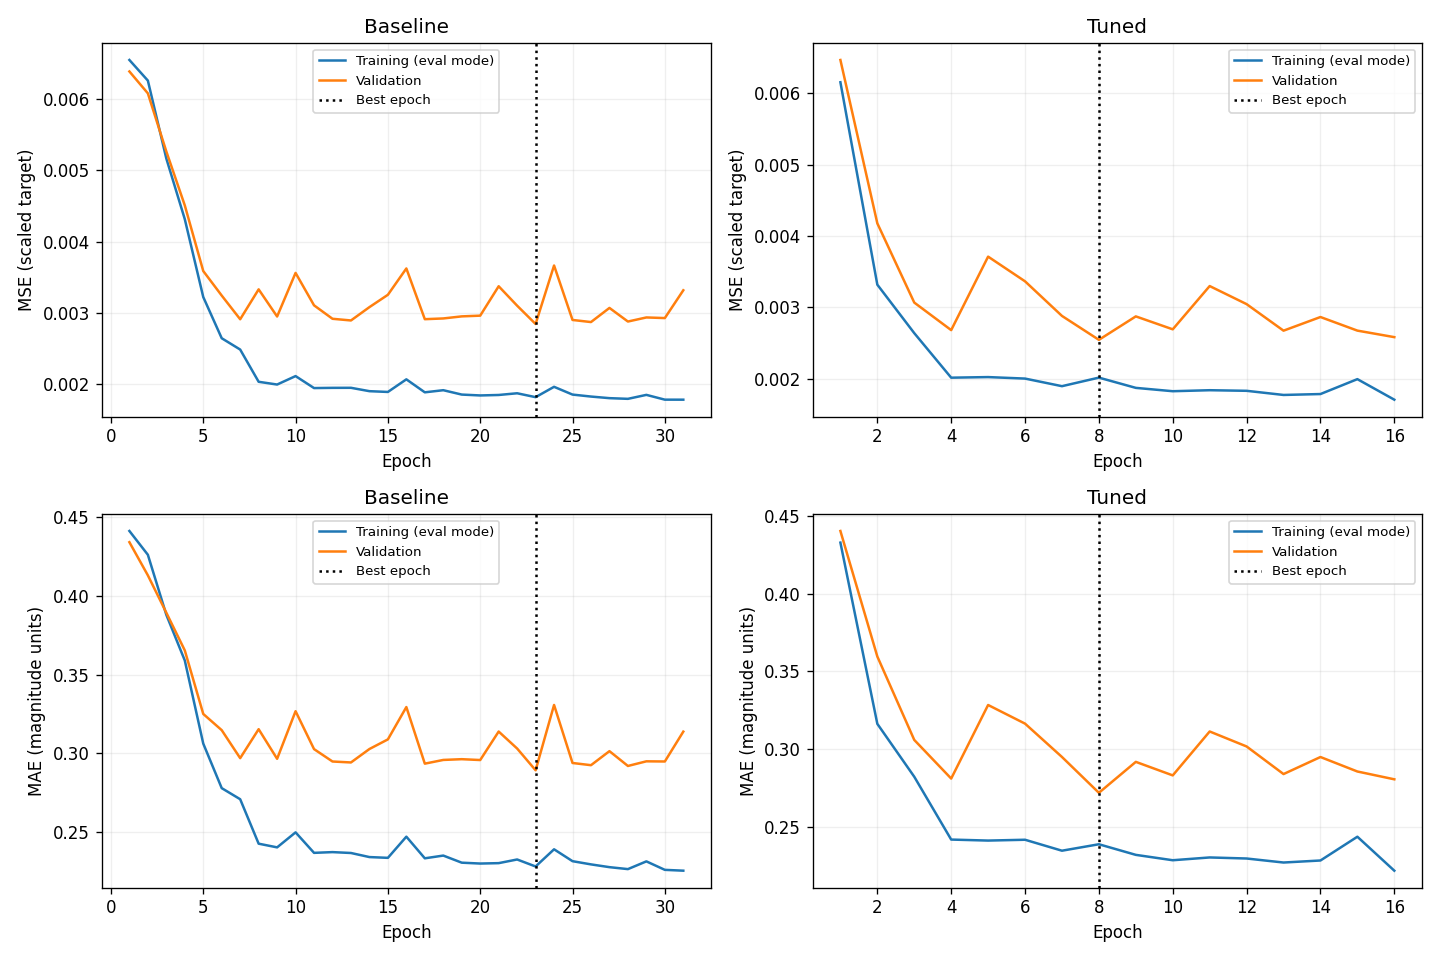

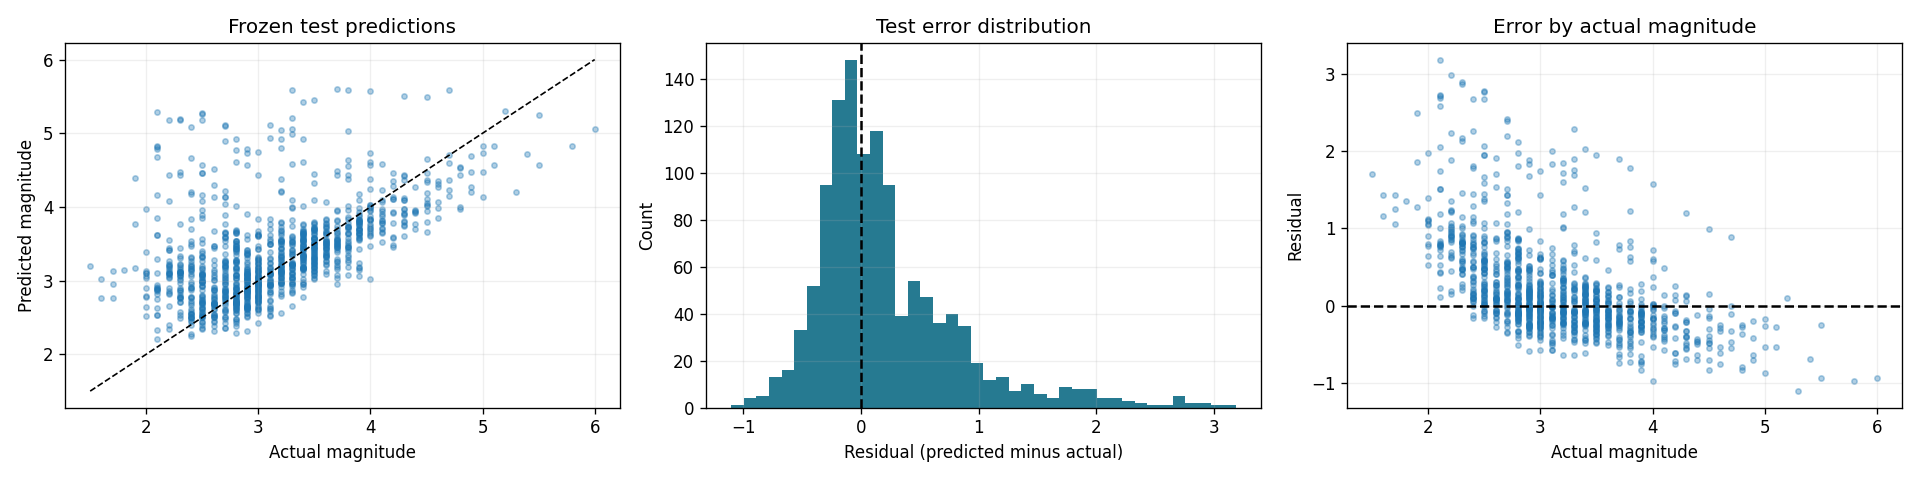

Final report: C:\Users\choud\Desktop\Minor project\bilstm\phase2_bilstm_results\final_report.md; total training: 2.85 min


In [6]:
plt.rcParams.update({"figure.dpi": 120, "axes.grid": True, "grid.alpha": 0.2})
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for col, name in enumerate(("baseline", "tuned")):
    h = history[history.model == name]
    summary = baseline_summary if name == "baseline" else tuned_summary
    for row, (train_col, val_col, ylabel) in enumerate((
        ("train_loss", "val_loss", "MSE (scaled target)"),
        ("train_mae", "val_mae", "MAE (magnitude units)"))):
        ax = axes[row, col]
        ax.plot(h.epoch, h[train_col], label="Training (eval mode)")
        ax.plot(h.epoch, h[val_col], label="Validation")
        ax.axvline(summary["best_epoch"], color="black", linestyle=":", label="Best epoch")
        ax.set(xlabel="Epoch", ylabel=ylabel, title=name.capitalize())
        ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUT / "training_validation_curves.png")
plt.close(fig)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].scatter(actual, predicted, s=10, alpha=0.35)
lo, hi = min(actual.min(), predicted.min()), max(actual.max(), predicted.max())
axes[0].plot([lo, hi], [lo, hi], "k--", linewidth=1)
axes[0].set(xlabel="Actual magnitude", ylabel="Predicted magnitude", title="Frozen test predictions")
axes[1].hist(predicted - actual, bins=40, color="#267a91")
axes[1].axvline(0, color="black", linestyle="--")
axes[1].set(xlabel="Residual (predicted minus actual)", ylabel="Count", title="Test error distribution")
axes[2].scatter(actual, predicted - actual, s=10, alpha=0.35)
axes[2].axhline(0, color="black", linestyle="--")
axes[2].set(xlabel="Actual magnitude", ylabel="Residual", title="Error by actual magnitude")
fig.tight_layout()
fig.savefig(OUT / "prediction_error_plots.png")
plt.close(fig)
range_frame = pd.DataFrame(ranges)
fig, ax = plt.subplots(figsize=(9, 4))
pos = np.arange(len(range_frame))
ax.bar(pos - 0.18, range_frame.mae, width=0.36, label="Tuned BiLSTM")
ax.bar(pos + 0.18, range_frame.mean_baseline_mae, width=0.36, label="Training mean")
ax.set_xticks(pos, [f"{r['magnitude_range']}\nn={r['n']}" for r in ranges])
ax.set(ylabel="MAE (magnitude units)", title="Test performance by magnitude")
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "performance_by_magnitude.png")
plt.close(fig)

overfitting = {}
for summary in (baseline_summary, tuned_summary):
    name = summary["run"]
    h = history[history.model == name].reset_index(drop=True)
    best_row = h.loc[h.epoch == summary["best_epoch"]].iloc[0]
    last_row = h.iloc[-1]
    gap = float(best_row.val_mae - best_row.train_mae)
    rise = float(last_row.val_mae - best_row.val_mae)
    train_change = float(last_row.train_mae - best_row.train_mae)
    divergent = rise > 0.02 * best_row.val_mae and train_change < 0
    verdict = ("Overfitting signal after the selected epoch: training MAE decreased while validation MAE rose."
               if divergent else "No clear post-selection divergence under the stated 2% validation-rise heuristic.")
    overfitting[name] = {"verdict": verdict,
                        "best_epoch_train_mae": float(best_row.train_mae),
                        "best_epoch_validation_mae": float(best_row.val_mae),
                        "best_epoch_validation_minus_train_mae": gap,
                        "last_minus_best_validation_mae": rise,
                        "last_minus_best_train_mae": train_change,
                        "caveat": "Curves do not establish leakage-free splits or future-event generalization."}
atomic_json(OUT / "overfitting_analysis.json", overfitting)
training_total = 0.0
for folder in (OUT / "runs").iterdir():
    if (folder / "history.csv").exists():
        training_total += float(pd.read_csv(folder / "history.csv").iloc[-1].elapsed_seconds)
atomic_json(OUT / "training_timing.json", {
    "total_training_seconds": training_total, "baseline_seconds": baseline_summary["training_seconds"],
    "tuned_seconds": tuned_summary["training_seconds"],
    "definition": "Synchronized training + development evaluation across unique runs; excludes setup and checkpoint I/O."})
table = ["| Model | Train MSE | Val MSE | Val MAE | Val RMSE | Best epoch | Epochs | Parameters | Training s |",
         "|---|---:|---:|---:|---:|---:|---:|---:|---:|"]
for s in (baseline_summary, tuned_summary):
    table.append(f"| {s['run']} | {s['train_loss']:.6f} | {s['validation_loss']:.6f} | "
                 f"{s['validation_mae']:.6f} | {s['validation_rmse']:.6f} | {s['best_epoch']} | "
                 f"{s['epochs_run']} | {s['parameter_count']} | {s['training_seconds']:.1f} |")
tm, bm = test_metrics["tuned"], test_metrics["training_mean_baseline"]
complete = sum(t.state == TrialState.COMPLETE for t in study.trials)
pruned = sum(t.state == TrialState.PRUNED for t in study.trials)
report = f"""# Phase 2 BiLSTM results

## Scope and research
Magnitude regression from supplied 20x36 windows. Last-layer final forward/backward states are concatenated, followed by dropout and a scalar head. AdamW/BPTT trains all weights and biases; no CNN, attention or evolutionary optimization.
[Graves & Schmidhuber (2005)](https://www.cs.toronto.edu/~graves/nn_2005.pdf), sections II-III, supplies the bidirectional principle, not the exact speech task or peephole cell.
Additional reference: [Schuster & Paliwal (1997)](https://doi.org/10.1109/78.650093).

## Data and target provenance
Source: {data_path.relative_to(ROOT)}. SHA256: {DATA_HASH}.
Train/validation/test: {len(DEV['train'][0])}/{len(DEV['val'][0])}/{len(actual)}.
No scaler object was supplied. The affine inverse recovered from saved training target pairs is raw = {SCALE:.10f} * scaled + {OFFSET:.10f}. Maximum development discrepancy: {max(max_inverse_error.values()):.3g}. Test pairs also pass the inverse check.
No timestamps, feature schema, event IDs, scaler-fitting provenance or causal target definition were supplied. Split independence and upstream leakage remain unverified. These are supplied-split magnitude-estimation scores, not evidence of future earthquake forecasting. Optional binary classification was omitted.

## Selection and training
Seed {SEED}; {environment['gpu'] or DEVICE}; max {MAX_EPOCHS} epochs, patience {PATIENCE}, clip norm 1.0.
Optuna TPE selected by validation MAE: {complete} completed, {pruned} pruned. Best trial {study.best_trial.number}, validation MAE {study.best_value:.6f}.
Selected hyperparameters: {json.dumps(BEST, sort_keys=True)}.
The tuned configuration was fitted separately with the same seed. Test data were not used for model selection.

{chr(10).join(table)}

Total physical training/development-evaluation time: {training_total:.1f} seconds ({training_total/60:.2f} minutes), counting each run once. Installation, checkpoint I/O and plotting are excluded.

## Frozen test evaluation
Tuned BiLSTM: MAE **{tm['mae']:.6f}**, RMSE **{tm['rmse']:.6f}**, R2 **{tm['r2']:.6f}**, n={tm['n']}.
Training mean baseline (constant {TRAIN_MEAN:.6f}): MAE **{bm['mae']:.6f}**, RMSE **{bm['rmse']:.6f}**, R2 **{bm['r2']:.6f}**.
One test prediction pass is saved for reuse. See performance_by_magnitude.csv for range-specific counts/MAE/RMSE/R2 and mean-baseline MAE; sparse high-magnitude groups require caution.

## Overfitting
Baseline: {overfitting['baseline']['verdict']}
Tuned: {overfitting['tuned']['verdict']}
Tuned best-epoch training/validation MAE: {overfitting['tuned']['best_epoch_train_mae']:.6f}/{overfitting['tuned']['best_epoch_validation_mae']:.6f}; gap {overfitting['tuned']['best_epoch_validation_minus_train_mae']:+.6f}.
Last-minus-best validation MAE: {overfitting['tuned']['last_minus_best_validation_mae']:+.6f}; training change: {overfitting['tuned']['last_minus_best_train_mae']:+.6f}.
The diagnostic flags a validation MAE rise above 2% of its best value while training MAE falls. This descriptive heuristic is not a statistical guarantee. Best-checkpoint selection mitigates late degradation; unresolved provenance limits interpretation.

## Artifacts and reproducibility
The executable notebook is ../phase2_bilstm.ipynb.
best_bilstm.pt contains weights, architecture, target definition, best epoch, hyperparameters and experiment identity. Strict reload and exact validation-prediction comparison passed.
Saved files include best_hyperparameters.json, optuna_study.db, training_history.csv, test_metrics.json, model_comparison.csv, target_transform.json, environment.json, experiment_manifest.json, training_timing.json, optuna_trials.csv and per-run resumable checkpoints.
Figures: training_validation_curves.png, prediction_error_plots.png, performance_by_magnitude.png.
Rerun all cells to reuse completed fits/search/test predictions. Interrupted fits restore optimizer/RNG/patience; abandoned trials are requeued. Determinism is environment-specific, not guaranteed across PyTorch/CUDA versions.
"""
(OUT / "final_report.md").write_text(report, encoding="utf-8")
assert all((OUT / name).exists() for name in (
    "best_bilstm.pt", "best_hyperparameters.json", "optuna_study.db",
    "training_history.csv", "test_metrics.json", "final_report.md"))
atomic_json(OUT / "verification.json", {
    "architecture": "BiLSTM + concatenated final states + dropout + scalar head",
    "adamw_all_parameters": True, "finite_gradients_both_directions": True,
    "validation_only_selection": True, "baseline_and_tuned_recorded": True,
    "strict_checkpoint_reload_and_prediction_match": True, "test_predictions_persisted": True,
    "overfitting_analysis_saved": True, "notebook_final_cell_reached": True, "experiment": EXPERIMENT})
display(Image(filename=str(OUT / "training_validation_curves.png")))
display(Image(filename=str(OUT / "prediction_error_plots.png")))
print(f"Final report: {OUT / 'final_report.md'}; total training: {training_total/60:.2f} min")
